# 06 - Modelo MLP (Red neuronal)

**Objetivo:** estimar `ORGC` (%) con una red neuronal MLP usando los archivos generados por `02_preprocesamiento.ipynb`.
**Referencia:** Carbajal et al. (2024), *Ecosystems* ([DOI](https://doi.org/10.1007/s10021-024-00928-7)), donde se compara RF, ANN, SVM y XGBoost para predecir SOC en los Andes de Junín.

**¿Cómo funciona una MLP?** Es una red neuronal de capas totalmente conectadas. Cada neurona combina las salidas de la capa anterior con unos pesos y aplica una activación (ReLU). Durante el entrenamiento, el optimizador (Adam) ajusta los pesos para reducir el error. A diferencia de los árboles, la red **sí necesita variables escaladas**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.inspection import permutation_importance

# Igual que en 02_modelos.ipynb: reutilizamos la evaluación del módulo src.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from evaluation import evaluate_models

## 1. Carga de datos

Se leen los CSV **escalados** de `data/processed` (`X_train_scaled.csv` y `X_test_scaled.csv`), porque la red es sensible a la escala de las variables. Son las mismas 8 variables y la misma división por perfil que usa el modelo Cubist, así que los resultados se pueden comparar.

In [2]:
RUTA = ROOT / 'data' / 'processed'
X_train = pd.read_csv(RUTA / 'X_train_scaled.csv')
X_test = pd.read_csv(RUTA / 'X_test_scaled.csv')
y_train = pd.read_csv(RUTA / 'y_train.csv')['ORGC']
y_test = pd.read_csv(RUTA / 'y_test.csv')['ORGC']
grupos = pd.read_csv(RUTA / 'groups_train.csv')['profile_code']

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Variables:', list(X_train.columns))
print('Perfiles en entrenamiento:', grupos.nunique())

Entrenamiento: (17338, 8) | Prueba: (4263, 8)
Variables: ['depth_mid', 'thickness', 'PHAQ', 'SILT', 'CLAY', 'TCEQ', 'ELCOSP', 'ECEC']
Perfiles en entrenamiento: 6564


## 2. Búsqueda de hiperparámetros

`ORGC` es muy asimétrica (la mayoría de capas tiene menos de 2 %), por eso la red aprende `log(1 + ORGC)` con `TransformedTargetRegressor`, y las predicciones se devuelven en %.

`GridSearchCV` con `GroupKFold` de 5 folds (agrupado por perfil, solo con entrenamiento) prueba:
- `hidden_layer_sizes`: número de capas ocultas y neuronas por capa.
- `alpha`: regularización L2; valores altos castigan los pesos grandes y reducen el sobreajuste.

Se usa *early stopping*: el entrenamiento se detiene cuando el error de validación interna deja de mejorar durante 20 épocas. Se minimiza el MAE.

In [3]:
def crear_mlp(capas=(64, 32), alpha=0.001):
    red = MLPRegressor(hidden_layer_sizes=capas, activation='relu', solver='adam',
                       alpha=alpha, learning_rate_init=0.001, batch_size=256, max_iter=500,
                       early_stopping=True, n_iter_no_change=20, random_state=42)
    return TransformedTargetRegressor(regressor=red, func=np.log1p, inverse_func=np.expm1)


PARAMETROS = {
    'regressor__hidden_layer_sizes': [(32,), (64, 32), (128, 64), (128, 64, 32)],
    'regressor__alpha': [0.0001, 0.01, 0.1, 1.0],
}

busqueda = GridSearchCV(crear_mlp(), param_grid=PARAMETROS, scoring='neg_mean_absolute_error',
                        cv=GroupKFold(n_splits=5), n_jobs=-1)
busqueda.fit(X_train, y_train, groups=grupos)

print('Mejores hiperparámetros:', busqueda.best_params_)
print('MAE CV (5 folds):', round(-busqueda.best_score_, 4))

Mejores hiperparámetros: {'regressor__alpha': 0.1, 'regressor__hidden_layer_sizes': (128, 64, 32)}
MAE CV (5 folds): 1.4606


In [4]:
cv_resultados = pd.DataFrame(busqueda.cv_results_)
tabla_cv = pd.DataFrame({
    'capas': cv_resultados['param_regressor__hidden_layer_sizes'].astype(str),
    'alpha': cv_resultados['param_regressor__alpha'],
    'MAE_CV': -cv_resultados['mean_test_score'],
    'DE_MAE': cv_resultados['std_test_score'],
}).sort_values('MAE_CV')
display(tabla_cv.head(10).round(4))

,capas,alpha,MAE_CV,DE_MAE
11,"(128, 64, 32)",0.1000,1.4606,0.0651
7,"(128, 64, 32)",0.0100,1.4685,0.0747
3,"(128, 64, 32)",0.0001,1.4727,0.0706
10,"(128, 64)",0.1000,1.4827,0.0699
9,"(64, 32)",0.1000,1.4920,0.0679
1,"(64, 32)",0.0001,1.4985,0.0624
2,"(128, 64)",0.0001,1.4986,0.0593
5,"(64, 32)",0.0100,1.4987,0.0645
6,"(128, 64)",0.0100,1.5027,0.0646
8,"(32,)",0.1000,1.5145,0.0585


## 3. Entrenamiento y evaluación

Se usa el mejor modelo de la búsqueda. Igual que en el notebook del Cubist, `evaluate_models()` de `src/evaluation.py` calcula las métricas en entrenamiento y prueba, en la escala original de `ORGC` (%).

In [5]:
modelo_mlp = busqueda.best_estimator_
resultados = evaluate_models({'MLP': modelo_mlp}, X_train, y_train, X_test, y_test)
display(resultados.pivot(index='Modelo', columns='Conjunto', values=['R2', 'RMSE', 'MAE', 'MedAE']).round(4))

R2            RMSE             MAE           MedAE        
Conjunto    test   train    test   train    test   train    test   train
Modelo                                                                  
MLP       0.1873  0.2392  4.9533  4.6312  1.3813  1.3475  0.3412  0.3309

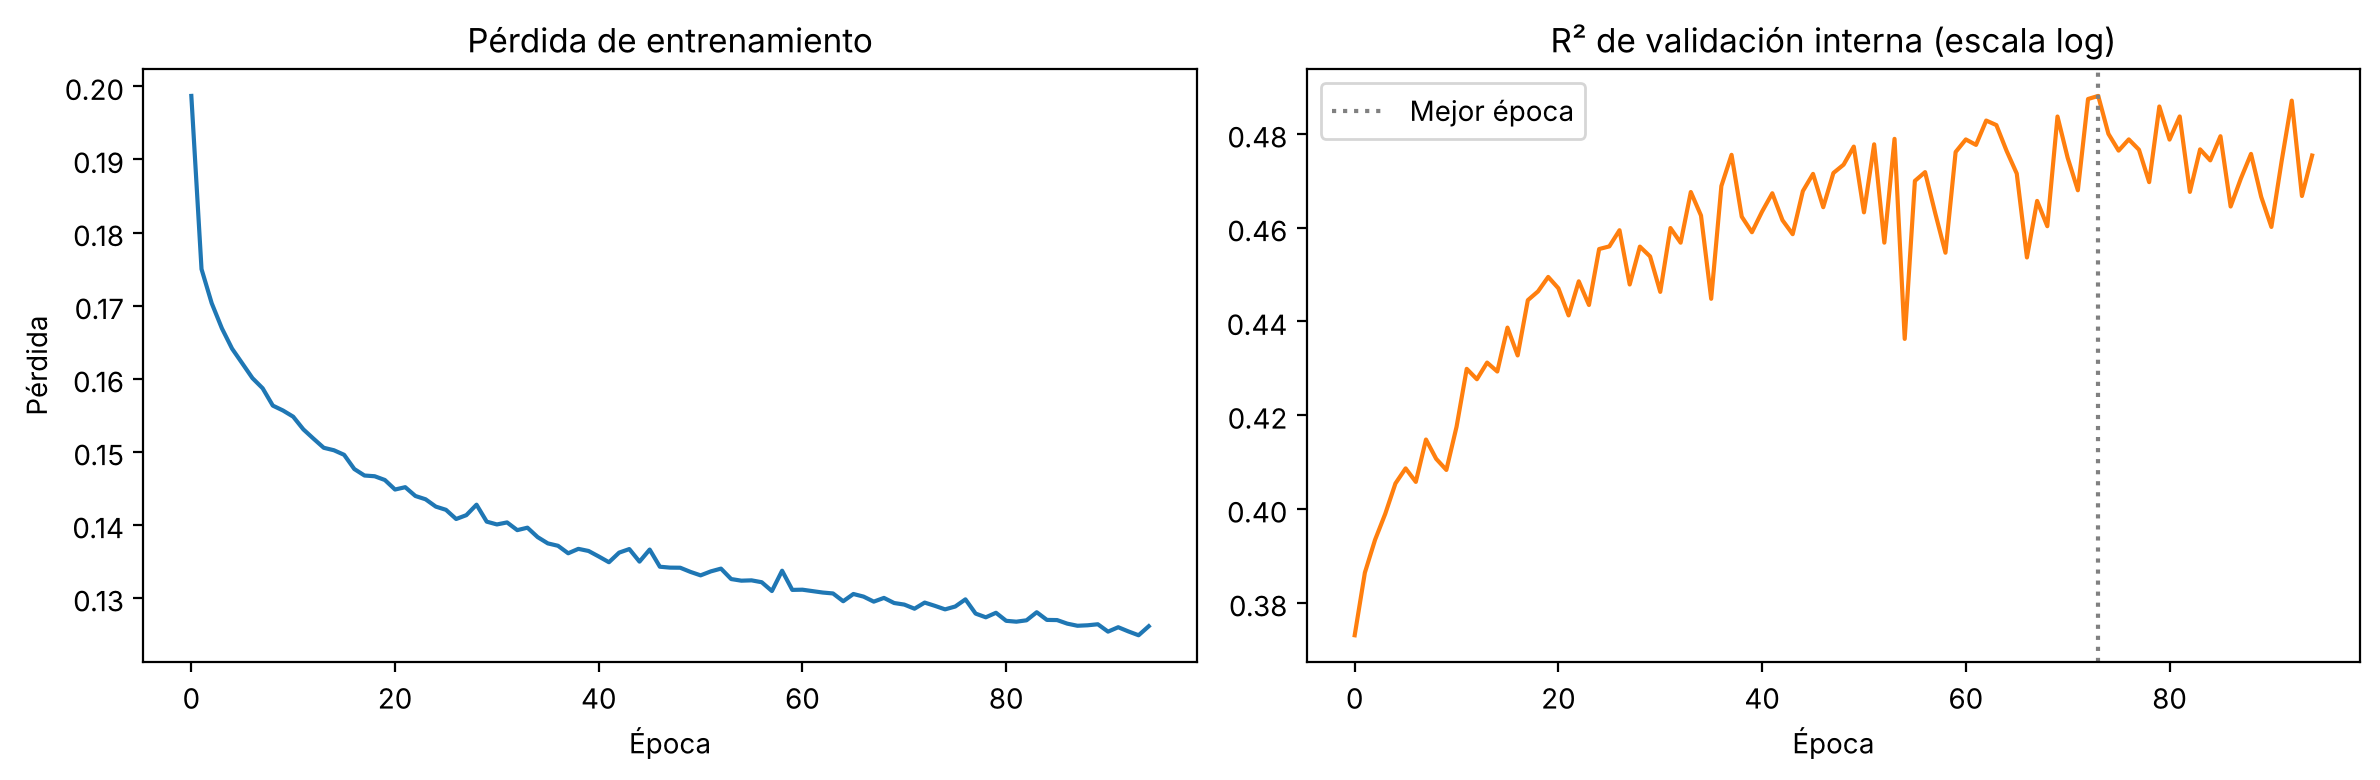

Épocas entrenadas: 95


In [6]:
# Curva de aprendizaje de la red final
red = modelo_mlp.regressor_
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(red.loss_curve_)
axes[0].set(title='Pérdida de entrenamiento', xlabel='Época', ylabel='Pérdida')
axes[1].plot(red.validation_scores_, color='tab:orange')
axes[1].axvline(np.argmax(red.validation_scores_), color='grey', ls=':', label='Mejor época')
axes[1].set(title='R² de validación interna (escala log)', xlabel='Época')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Épocas entrenadas:', red.n_iter_)

## 4. Análisis de predicciones

Se comparan los valores observados y predichos sobre el conjunto de prueba. La línea diagonal representa una predicción perfecta.

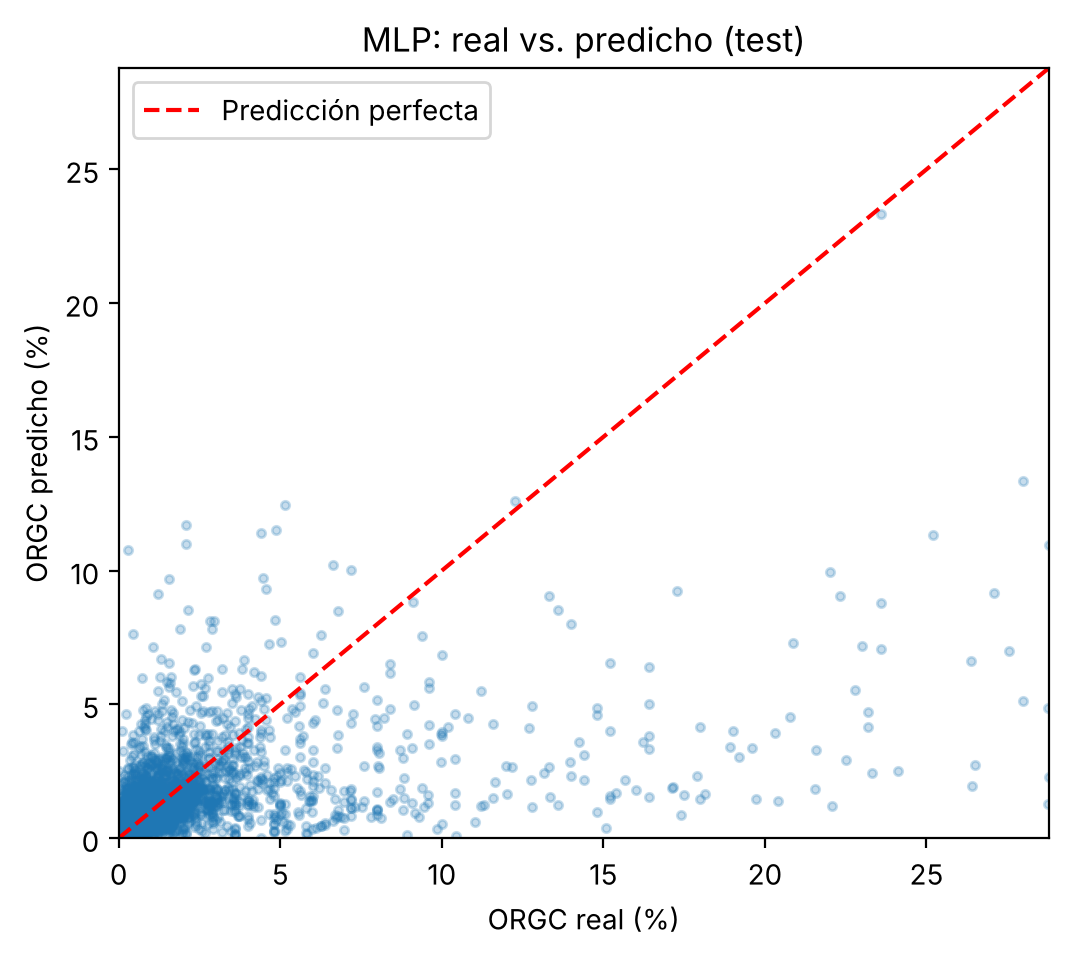

Predicciones negativas: 6


In [7]:
pred = modelo_mlp.predict(X_test)
limite = np.quantile(y_test, 0.99)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred, alpha=0.25, s=9)
ax.plot([0, limite], [0, limite], 'r--', label='Predicción perfecta')
ax.set(xlim=(0, limite), ylim=(0, limite),
       xlabel='ORGC real (%)', ylabel='ORGC predicho (%)',
       title='MLP: real vs. predicho (test)')
ax.legend()
plt.show()

print('Predicciones negativas:', (pred < 0).sum())

In [8]:
# Error por rango de carbono: dónde acierta y dónde falla la red
error = np.abs(y_test - pred)
rangos = pd.cut(y_test, bins=[0, 1, 3, 10, 100], labels=['<1 %', '1-3 %', '3-10 %', '>10 %'], include_lowest=True)
tabla_rangos = pd.DataFrame({
    'Capas': rangos.value_counts().sort_index(),
    'MAE (%)': error.groupby(rangos, observed=False).mean().round(3),
})
display(tabla_rangos)

# Aciertos con una tolerancia en puntos de % de carbono
for t in [0.25, 0.5, 1]:
    print(f'Error <= {t} %: {(error <= t).mean() * 100:.1f} % de las capas')

,Capas,MAE (%)
ORGC,,
<1 %,2697,0.379
1-3 %,1062,0.828
3-10 %,367,3.006
>10 %,137,21.044


Error <= 0.25 %: 40.6 % de las capas
Error <= 0.5 %: 60.5 % de las capas
Error <= 1 %: 78.4 % de las capas


### Importancia de variables

La MLP no tiene `feature_importances_` como los árboles, por eso se usa **importancia por permutación**: se desordena una variable en el conjunto de prueba y se mide cuánto aumenta el MAE. Si el error sube mucho, la variable es importante.

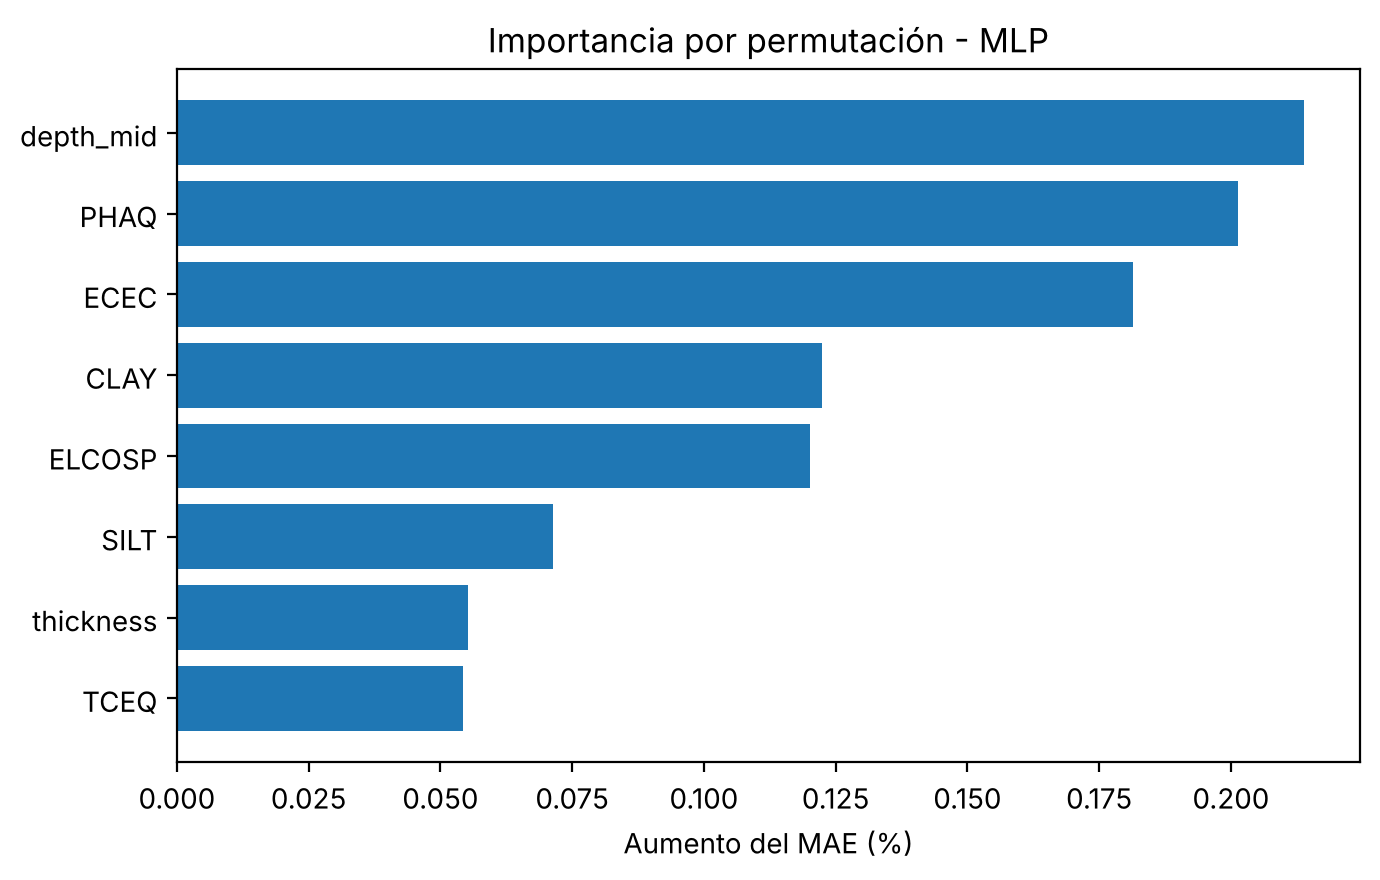

In [9]:
perm = permutation_importance(modelo_mlp, X_test, y_test, scoring='neg_mean_absolute_error',
                              n_repeats=10, random_state=42, n_jobs=-1)
importancias = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importancias.index, importancias.values)
ax.set(title='Importancia por permutación - MLP', xlabel='Aumento del MAE (%)')
plt.tight_layout()
plt.show()

## 5. Comparación con modelos de referencia

Con los mismos datos de `data/processed` se entrenan tres referencias simples (media, mediana y regresión lineal). También se incluyen los resultados del Cubist (`cubist_model_Integrante2.ipynb`), que usa la misma división.

In [10]:
referencias = {
    'Media': DummyRegressor(strategy='mean'),
    'Mediana': DummyRegressor(strategy='median'),
    'Regresión Lineal': LinearRegression(),
    'MLP': modelo_mlp,
}
res = evaluate_models(referencias, X_train, y_train, X_test, y_test)
comparacion = res[res['Conjunto'] == 'test'].set_index('Modelo')[['R2', 'RMSE', 'MAE', 'MedAE']]

# Resultados de prueba del notebook cubist_model_Integrante2.ipynb
comparacion.loc['Cubist'] = [0.2202, 4.8521, 1.6624, np.nan]
display(comparacion.loc[['Media', 'Mediana', 'Regresión Lineal', 'Cubist', 'MLP']].round(4))

,R2,RMSE,MAE,MedAE
Modelo,,,,
Media,-0.0001,5.4947,2.1849,1.5235
Mediana,-0.0537,5.6400,1.6597,0.4900
Regresión Lineal,0.0939,5.2300,2.1736,1.3490
Cubist,0.2202,4.8521,1.6624,NaN
MLP,0.1873,4.9533,1.3813,0.3412


### Interpretación

- **La MLP tiene el menor error típico:** MAE de 1.38 y MedAE de 0.34 en prueba, mejores que el Cubist (MAE 1.66) y que las referencias. El 78 % de las capas tiene un error menor o igual a 1 punto de % de carbono.
- **Pero su R² (0.19) es menor que el del Cubist (0.22) y su RMSE es mayor.** La tabla por rangos muestra la razón: la red acierta mucho en suelos con ORGC < 3 % (MAE de 0.38 y 0.83), que son la mayoría, pero falla en los 137 suelos con ORGC > 10 % (MAE de 21). El R² y el RMSE elevan el error al cuadrado, así que esos pocos suelos pesan mucho.
- **Esto se debe a entrenar sobre `log(1 + ORGC)`:** la escala log ayuda en los valores bajos, que son la mayoría, y comprime los valores altos.
- **Casi no hay sobreajuste:** R² de 0.24 en entrenamiento y 0.19 en prueba (el Cubist pasa de 0.60 a 0.22). La regularización (`alpha = 0.1`) y el *early stopping* (95 épocas) cumplen su función.
- **Frente al paper de referencia:** Carbajal et al. (2024) obtienen R² = 0.43 con su ANN, pero usando uso del suelo, índices satelitales y clima. Aquí solo hay 8 variables edáficas, por lo que el límite lo pone la información disponible más que el algoritmo, como también concluyen los autores.
- **Limitación:** la mejor arquitectura fue la más grande de la búsqueda, (128, 64, 32); redes más grandes podrían mejorar un poco, aunque con más riesgo de sobreajuste.
